In [ ]:
### Quick Recap

# "Objects" are a programming structure that joins functions and data together
# That is, "objects" are structures with "methods" (i.e., functions) and "attributes" (i.e., data)
# You can access or use an object's methods or functions using: <object>.<attributes/methods>
# Lists are one example of an object and they have a .sort() method that sorts the elements of the list
l = [1,6,2]
l.sort() # here we are using the sort method of the list object "l"
# Most things in Python are objects

# Importing libraries
# basic way of importing a library
import numpy
# import a library under an alias
import numpy as np
# import just a specific set of functions from a library
from numpy import array, unique, arange




In [ ]:
### Numpy
# numpy is probably the most useful and widely used Python library for neuroimaging
# It gives you access to lots of numerical functions (e.g., interpolation, filtering, random numbers)
# and implements a very useful data structure called an "array"
# There is also an "array" object that is native to Python, but it's not used much in neuroimaging because
# numpy is ubiquitous and offers more features.

In [ ]:
### Arrays
# an array is basically a matrix with arbitrarily many dimensions
# (or more accurately a "tensor", because strictly speaking matrices are 2D)
import numpy as np
#an easy way to create an array is to write a list and convert it to an array
myArray = np.array( [ [1,2,3], [4,5,6]] )

#arrays can be indexed, much like lists
print(myArray[0])
print(myArray[1])
print(myArray[0][0])
print(myArray[1][2])



# Unlike lists, arrays must have:
#    1. Elements that are all of the same data type
myList0 = [ 0, 1]
print( np.array(myList0))
myList1 = [ 0, True, 'v'] # numpy will automatically convert lists with multiple types, so be careful
print(np.array(myList1))

#    2. Have dimensions (or 'axes') of the same length

myList0 = [ 0, [1],[[1],2]] # works fine as a list, but causes weird behaviour when converted to a numpy array
print(np.array(myList0))


In [ ]:
# Numpy arrays have lots of useful "attributes"

animals = np.array([['cat', 'dog'],['snake', 'rhino'], ['monkey', 'spider']])
print(animals)

# .shape tells you the size of each dimension in the array
print(animals.shape)

# .dtype tells you the data type of the array
print(animals.dtype)


In [ ]:
### EXCERCISE

animals = np.array([['cat', 'dog'],['snake', 'rhino'], ['monkey', 'spider']])

# Use for-loops, range, and .shape to print each element in the "animals" array


In [ ]:






### SOLUTION
animals = np.array([['cat', 'dog'],['snake', 'rhino'], ['monkey', 'spider']])
for i in range(animals.shape[0]) :
    for j in range(animals.shape[1]) :
        print(animals[i][j])


In [5]:
# Slicing
# What if you only want to access a subset of an array?
# You can use "slicing" to access a part of an array
# Examples 1, 2, and 3b will work for lists too
import numpy as np
ar = np.array([[0,2,4,6,8,10,12],[1,3,5,7,9,11,13],[1,1,3,5,8,13,21]])
print('ar:')
print(ar)
print('\nshape',ar.shape, '\n')

print('first element:', ar[1][1])

print('1.a)', ar[0][0:4]) #this will return the 0th, 1st, and 2nd elements of the 0th row
print('1.b)', ar[0][:4]) # select from start to 2nd entry

print('2.a)', ar[1][3:]) #select from 3rd entry to the end of this dimension
print('2.b)', ar[1][3:8])

print('3.a)', ar[2][[0,2,4,6]]) # can use integers to index individual elements
print('3.b)', ar[2][0:8:2])

print('4)', ar[2][:]) # select all elements in this dimension

ar:
[[ 0  2  4  6  8 10 12]
 [ 1  3  5  7  9 11 13]
 [ 1  1  3  5  8 13 21]]

shape (3, 7) 

first element: 3
1.a) [0 2 4 6]
1.b) [0 2 4 6]
2.a) [ 7  9 11 13]
2.b) [ 7  9 11 13]
3.a) [ 1  3  8 21]
3.b) [ 1  3  8 21]
4) [ 1  1  3  5  8 13 21]


In [ ]:
### Zeros & Ones
# You can create arrays of zeros and ones with np.zeros(<dimensions>) and np.arrays(<dimensions>)
# with a given set of dimensions
print('a')
two_by_two = np.ones([2,2])
print(two_by_two)

print('\nb')
zeros_3d = np.zeros([3,3,3])
print(zeros_3d)


In [ ]:
### Reshaping arrays
# It can be useful to reshape an array to different dimensions.
# The .reshape(<new dimensions>) function lets you do this.
# for example an array with a single dimension of [27] can be
# reshaped into an array of shape [3,3,3]
vector = np.arange(27) # np.arange() is a function that returns an array of floats (similar to range() but not quite the same)
print('\nvector\n', vector)
matrix = vector.reshape(3,9)
print('\nmatrix\n',matrix)
volume = matrix.reshape(3,3,3)
print('\nvolume\n',volume)

In [6]:
!git clone https://github.com/tfunck/hacking_hour

Cloning into 'hacking_hour'...
remote: Enumerating objects: 175, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (140/140), done.
remote: Total 175 (delta 64), reused 81 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (175/175), 4.90 MiB | 10.23 MiB/s, done.
Resolving deltas: 100% (64/64), done.


The brain image stored at hacking_hour/data/full16_1000um_optbal.nii.gz has dimensions (x,y,z) = (140, 154, 121)
(154, 121)


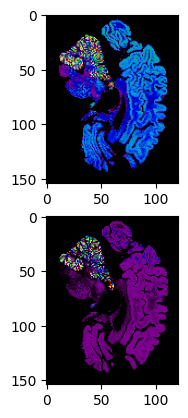

In [16]:
### Why do arrays matter for brain imaging?
# Brain sections (2d) and volumes (3d) are represented using arrays!

import nibabel as nib #import a library for reading and writing brain images in (almost) any file format
import matplotlib.pyplot as plt # import a library for plotting stuff and displaing 2D images

brain_filename='hacking_hour/data/full16_1000um_optbal.nii.gz'
brain_image = nib.load(brain_filename) # use nibabel method .load() to open the nifti filepath
brain_volume = brain_image.get_fdata() # use the .get_fdata() method to load the 3D brain volume

print(f'The brain image stored at {brain_filename} has dimensions (x,y,z) = {brain_volume.shape}')

dimension = 0

mid_point = int(brain_volume.shape[dimension]/2) # calculate the mid point of the z dimension

# select a brain slice from (about) the middle of the z-axis
if dimension == 2 :
  brain_slice = brain_volume[:,:,mid_point]
elif dimension == 1 :
  brain_slice = brain_volume[:,mid_point,:]
else :
  brain_slice = brain_volume[mid_point,:,:]


brain_slice = brain_slice.max() - brain_slice

brain_slice_2 = brain_slice ** 2

print(brain_slice.shape)
# Use the .imshow() method of the matplotlib.pyplot library to show the brain slice
plt.subplot(2,1,1)
plt.imshow(brain_slice, cmap='nipy_spectral')
plt.subplot(2,1,2)
plt.imshow(brain_slice_2, cmap='nipy_spectral')


In [ ]:
# can do operations on arrays. here we invert the color scheme for the brain slice
brain_slice_inverted = brain_slice.max()  - brain_slice
plt.imshow(brain_slice_inverted)

In [ ]:
### Excercise
# Numpy has lots of math functions (sin,cos,log,sqrt,etc.)
# Apply one (or more) mathemetical operations to brain_slice_inverted
# You can also apply standard mathematical operations to arrays (+,-,/,*), e.g., ar *= 2 will multiply ar by 2
# Display your modified image with plt.imshow(<your new brain slice>)


In [ ]:





### Solution
brain_slice_sin = np.sin(brain_slice_inverted)
plt.imshow(brain_slice_sin)

In [ ]:
### Excercise
# You can "smooth" images by blurring them with filters such as the Gaussian filter
# Scipy implements a gaussian filter(<image>, <standard deviation>):
from scipy.ndimage.filters import gaussian_filter

#apply gaussian_filter to brain_slice_inverted with a few different size standard deviations
# and display them with plt.imshow()


In [ ]:






### Solution

from scipy.ndimage.filters import gaussian_filter
brain_slice_smoothed = gaussian_filter(brain_slice_inverted,6)
plt.imshow(brain_slice_smoothed)

In [ ]:
### Slicing arrays with arrays
# It can often be convenient to create an array of booleans (i.e., True/False)
# to create an image "mask". The mask is True (or 1) in your region of interest and False (or 0) outside

# calculate 75% of the maximum pixel intensity in brain_slice_inverted
threshold_value = brain_slice_inverted.max() * 0.2

# create a new array where pixels are True (1) if they are less than the threshold and False otherwise
my_mask = brain_slice_inverted > threshold_value

print('myMask has a shape of ', my_mask.shape, 'and a data type of', my_mask.dtype)

plt.imshow(my_mask)


In [ ]:
# Using a mask to select pixels within an image

# .copy() is a method for numpy arrays that creates a copy of an array
brain_slice_masked = brain_slice_inverted.copy()

# When using numpy arrays, '~' is a boolean operator that means "not". It flips True to False and vice versa
# We invert the mask so that everything < 20% of the image mask is True (1) and everything else is False (0)
mask_inverted = ~ my_mask

brain_slice_masked[ mask_inverted ] = 0

plt.imshow(brain_slice_masked)

In [ ]:
### EXCERCISE

# Write a function that       1) takes a 3D array as input AND a standard deviation AND a threshold percentage
#                             2) blurs it with gaussian_filter() with the standard deviation passed to the function
#                             3) uses the the threshold percentage to create a mask based on the blurred image

# Write another function that 1) takes a brain image filename as input AND a standard deviation AND a threshold percentage value
#                             2) uses nibabel to open it
#                             3) uses .get_fdata() to load the 3D volume
#                             4) creates a mask of the brain volume using the first function
#                             5) returns the 3D volume as an array

# Display a section from the masked image using plt.imshow()

# BONUS POINTS: in the second function check if the file exists before trying to open it

brain_filename='data/full16_1000um_optbal.nii.gz'

import os
import nibabel as nib
from scipy.ndimage.filters import gaussian_filter

In [ ]:
import os
import nibabel as nib
from scipy.ndimage.filters import gaussian_filter

def threshold(vol, sd, threshold_percentage):
    vol_blur = gaussian_filter(vol,sd)
    threshold_value = vol_blur.max() * threshold_percentage
    mask = vol_blur > threshold_value
    return mask

def brain_mask_from_file(filename, sd, threshold_percentage) :
    if os.path.exists(filename):
        image = nib.load(filename)
        volume = image.get_fdata()
        mask = threshold(volume,sd,threshold_percentage)
    else :
        print('Error: file does not exist:',filename)
        mask=None

    return mask

brain_filename='hacking_hour/data/full16_1000um_optbal.nii.gz'
mask = brain_mask_from_file(brain_filename, 1, 0.85)

y_mid_point = int(mask.shape[1]/2)
plt.imshow(mask[:,y_mid_point,:])

